In [12]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from torch.utils.data import TensorDataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


In [13]:
class WideAndDeep(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features, 50),
            nn.ReLU(),
            nn.Linear(50, 40),
            nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features, 1)

    def forward(self, X):
        deep_output = self.deep_stack(X)
        wide_n_deep = torch.cat([X, deep_output], dim=1)
        return self.output_layer(wide_n_deep)


In [14]:
housing = fetch_california_housing(as_frame=True)
X = housing.data.values.astype('float32')
y = housing.target.values.astype('float32').reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val,  y_train, y_val  = train_test_split(X_train, y_train, test_size=0.1, random_state=42)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_val   = scaler.transform(X_val).astype('float32')
X_test  = scaler.transform(X_test).astype('float32')

def to_t(a): return torch.tensor(a).to(device)

Xt, yt   = to_t(X_train), to_t(y_train)
Xv, yv   = to_t(X_val),   to_t(y_val)
Xte, yte = to_t(X_test),  to_t(y_test)


In [15]:
model     = WideAndDeep(X_train.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)
dl        = DataLoader(TensorDataset(Xt, yt), batch_size=256, shuffle=True)

train_losses, val_losses = [], []

for epoch in range(100):
    model.train()
    bloss = []
    for Xb, yb in dl:
        optimizer.zero_grad()
        loss = criterion(model(Xb).squeeze(1), yb.squeeze(1))
        loss.backward()
        optimizer.step()
        bloss.append(loss.item())
    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(Xv).squeeze(1), yv.squeeze(1)).item()
    train_losses.append(np.mean(bloss))
    val_losses.append(val_loss)
    scheduler.step()


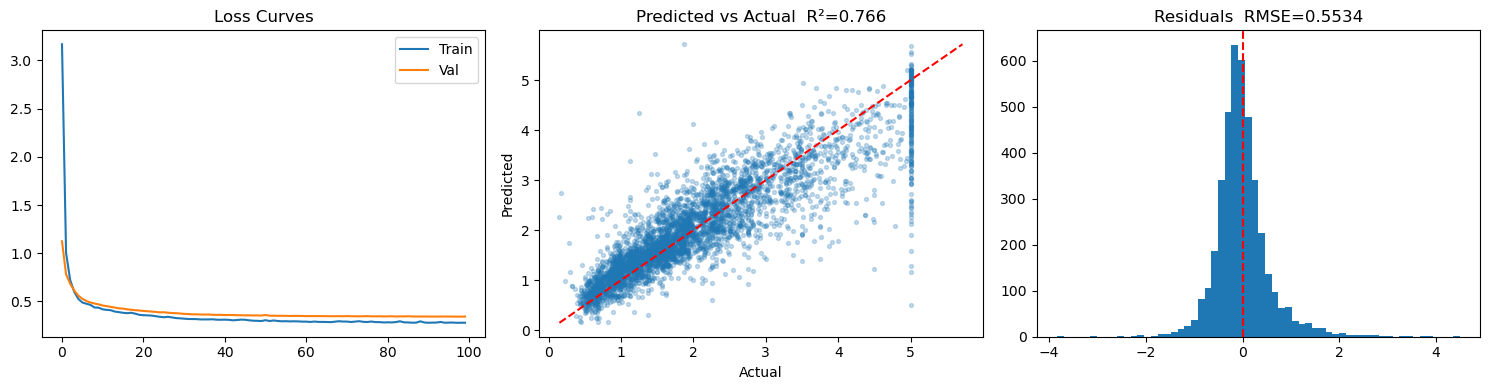

In [16]:
model.eval()
with torch.no_grad():
    preds = model(Xte).squeeze().cpu().numpy()
actual = y_test.squeeze()

mse  = mean_squared_error(actual, preds)
r2   = r2_score(actual, preds)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(train_losses, label='Train')
axes[0].plot(val_losses, label='Val')
axes[0].set_title('Loss Curves'); axes[0].legend()

axes[1].scatter(actual, preds, alpha=0.25, s=8)
lims = [min(actual.min(), preds.min()), max(actual.max(), preds.max())]
axes[1].plot(lims, lims, 'r--')
axes[1].set_title(f'Predicted vs Actual  R²={r2:.3f}')
axes[1].set_xlabel('Actual'); axes[1].set_ylabel('Predicted')

axes[2].hist(actual - preds, bins=60)
axes[2].axvline(0, color='r', linestyle='--')
axes[2].set_title(f'Residuals  RMSE={mse**0.5:.4f}')

plt.tight_layout()
plt.show()
